In [6]:
# Ternary Moiety 3D Interactive Plot
# Loads moiety triplet data from pkl files and creates 3D scatter plot

import os
import sys
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
from collections import Counter, defaultdict

# Add project root to path
# Find project root by looking for the 'config' and 'modules' directories
def find_project_root():
    # Start from current working directory
    current = os.getcwd()
    
    # Walk up until we find the project root (contains 'config' and 'modules' dirs)
    for _ in range(10):  # Max 10 levels up
        if os.path.isdir(os.path.join(current, "config")) and os.path.isdir(os.path.join(current, "modules")):
            return current
        parent = os.path.dirname(current)
        if parent == current:  # Reached filesystem root
            break
        current = parent
    
    raise FileNotFoundError("Run this notebook from within the HELENA repository.")

PROJECT_ROOT = find_project_root()
sys.path.insert(0, PROJECT_ROOT)

from config.paths import DATA_DIR

# Path to ternary intermediates
TERNARY_INTERMEDIATES_DIR = os.path.join(DATA_DIR, "inference_postprocess", "ternary")

In [7]:
# -----------------------------------------------------
# 1. LOAD DATA FROM PKL FILES
# -----------------------------------------------------

# Load moiety triplet data
moiety_triplet_path = os.path.join(TERNARY_INTERMEDIATES_DIR, "moiety_triplet_data.pkl")

if not os.path.exists(moiety_triplet_path):
    print(f"ERROR: Intermediate files not found at {moiety_triplet_path}")
    print("Please run generate_intermediates.py first.")
else:
    with open(moiety_triplet_path, "rb") as f:
        moiety_triplet_data = pickle.load(f)
    print(f"Loaded {len(moiety_triplet_data)} salt combination datasets")

# Select a salt combination to visualize
# Available keys are tuples: (salt_combo_type, salt_key, display_name)
print("\nAvailable salt combinations:")
for i, key in enumerate(moiety_triplet_data.keys()):
    salt_combo, salt_key, display_key = key
    print(f"  {i+1}. {display_key} ({len(moiety_triplet_data[key])} formulations)")

# Select the first available combination (or change this to select a specific one)
selected_key = list(moiety_triplet_data.keys())[0]
salt_combo, salt_key, display_key = selected_key
triplets = moiety_triplet_data[selected_key]

print(f"\nSelected: {display_key}")
print(f"Number of formulations: {len(triplets)}")

Loaded 9 salt combination datasets

Available salt combinations:
  1. DFOB + FSI (280690 formulations)
  2. FSI + PF6 (165027 formulations)
  3. PF6 + TFSI (37028 formulations)
  4. FSI + TFSI (15445 formulations)
  5. DFOB + PF6 (6150 formulations)
  6. PF6 (30 formulations)
  7. DFOB + TFSI (12 formulations)
  8. FSI (38 formulations)
  9. DFOB (1 formulations)

Selected: DFOB + FSI
Number of formulations: 280690


In [8]:
# -----------------------------------------------------
# 2. ANALYSIS OF MOIETY TRIPLETS
# -----------------------------------------------------

# Build triplet counts from loaded data
triplet_counts = defaultdict(int)

for triplet in triplets:
    for m1 in triplet["moieties1"]:
        for m2 in triplet["moieties2"]:
            for m3 in triplet["moieties3"]:
                triplet_counts[(m1, m2, m3)] += 1

print(f"Total unique triplet combinations: {len(triplet_counts)}")

# Sort triplets by count and get top patterns
top_patterns = sorted(triplet_counts.items(), key=lambda x: x[1], reverse=True)[:50]

# Extract unique moieties for each position
unique_m1 = sorted(set(triplet[0] for triplet, _ in top_patterns))
unique_m2 = sorted(set(triplet[1] for triplet, _ in top_patterns))
unique_m3 = sorted(set(triplet[2] for triplet, _ in top_patterns))

print(f"Unique moieties in position 1: {len(unique_m1)}")
print(f"Unique moieties in position 2: {len(unique_m2)}")
print(f"Unique moieties in position 3: {len(unique_m3)}")

# Create mapping from moiety to index
m1_to_idx = {m: i for i, m in enumerate(unique_m1)}
m2_to_idx = {m: i for i, m in enumerate(unique_m2)}
m3_to_idx = {m: i for i, m in enumerate(unique_m3)}

# Filter pattern data to only include top moieties
filtered_patterns = []
for (m1, m2, m3), count in top_patterns:
    if m1 in m1_to_idx and m2 in m2_to_idx and m3 in m3_to_idx:
        filtered_patterns.append(((m1, m2, m3), count))

# Extract data for plotting
counts = np.array([count for _, count in filtered_patterns])
max_count = max(counts)
min_count = min(counts)
x = np.array([m1_to_idx[m1] for (m1, m2, m3), _ in filtered_patterns])
y = np.array([m2_to_idx[m2] for (m1, m2, m3), _ in filtered_patterns])
z = np.array([m3_to_idx[m3] for (m1, m2, m3), _ in filtered_patterns])

print(f"\nTop 5 patterns:")
for i, ((m1, m2, m3), count) in enumerate(top_patterns[:5]):
    print(f"  {i+1}. ({m1}, {m2}, {m3}): {count}")

Total unique triplet combinations: 2941
Unique moieties in position 1: 6
Unique moieties in position 2: 5
Unique moieties in position 3: 7

Top 5 patterns:
  1. (secondary_carbon, secondary_carbon, methyl): 4584073
  2. (secondary_carbon, secondary_carbon, secondary_carbon): 4411442
  3. (fluoro, secondary_carbon, secondary_carbon): 4371740
  4. (fluoro, secondary_carbon, methyl): 4348220
  5. (fluoro, methyl, secondary_carbon): 3215225


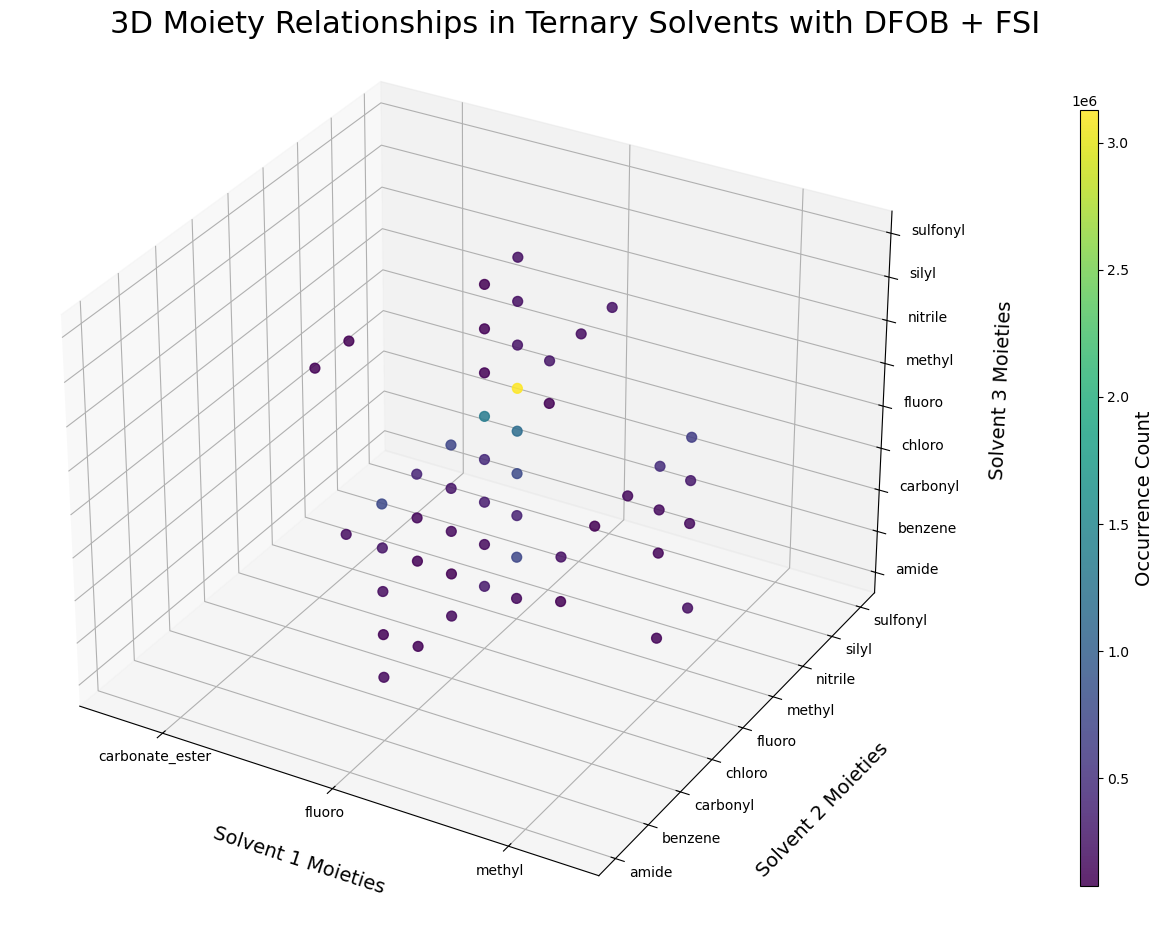

In [7]:
# -----------------------------------------------------
# 3. 3D VISUALIZATION
# -----------------------------------------------------

# Create a new figure
fig = plt.figure(figsize=(18, 12))

# Set subplot position
ax = fig.add_subplot(111, projection="3d")

# Set title using the display key from loaded data
fig.suptitle(f"3D Moiety Relationships in Ternary Solvents with {display_key}", fontsize=22, x=0.57 , y=0.88, ha='center')

# Plot data
scatter = ax.scatter(x, y, z, c=counts, cmap="viridis", s=50, alpha=0.85)

# Set axes limits
ax.set_xlim(-0.5, len(unique_m1) - 0.5)
ax.set_ylim(-0.5, len(unique_m2) - 0.5)
ax.set_zlim(-0.5, len(unique_m3) - 0.5)

# Set ticks
ax.set_xticks(range(len(unique_m1)))
ax.set_yticks(range(len(unique_m2)))
ax.set_zticks(range(len(unique_m3)))

# Tick label styling parameters
ticksize = 10
x_tick_ha = "center"
x_tick_va = "top"
y_tick_ha = "left"
y_tick_va = "center"
z_tick_ha = "left"
z_tick_va = "center"
x_tick_pad = 1
y_tick_pad = 1
z_tick_pad = 1

# Get the height of the 3D plot
bbox = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
height_in_inches = bbox.height
another_element_size = height_in_inches * 0.07

# Set tick labels with custom alignment
ax.set_xticklabels(unique_m1, rotation=0, ha=x_tick_ha, va=x_tick_va, fontsize=ticksize)
ax.set_yticklabels(unique_m2, rotation=0, ha=y_tick_ha, va=y_tick_va, fontsize=ticksize)
ax.set_zticklabels(unique_m3, rotation=0, ha=z_tick_ha, va=z_tick_va, fontsize=ticksize)

# Adjust tick padding
ax.tick_params(axis="x", pad=x_tick_pad)
ax.tick_params(axis="y", pad=y_tick_pad, labelright=False, labelleft=True)
ax.tick_params(axis="z", pad=z_tick_pad, labelright=False, labelleft=True)

# Set axis labels
label_fontsize = 14

# Calculate label padding based on tick label length
max_x_tick_len = max(len(label) for label in unique_m1) if unique_m1 else 1
max_y_tick_len = max(len(label) for label in unique_m2) if unique_m2 else 1
max_z_tick_len = max(len(label) for label in unique_m3) if unique_m3 else 1

x_labelpad = max_y_tick_len * 2
y_labelpad = max_y_tick_len * 4
z_labelpad = max_z_tick_len * 4

ax.set_xlabel("Solvent 1 Moieties", fontsize=label_fontsize, labelpad=x_labelpad)
ax.set_ylabel("Solvent 2 Moieties", fontsize=label_fontsize, labelpad=y_labelpad)
ax.set_zlabel("Solvent 3 Moieties", fontsize=label_fontsize, labelpad=z_labelpad)

# Add colorbar
cbar_ax = fig.add_axes([0.85, 0.15, 0.01, another_element_size])
cbar = fig.colorbar(scatter, cax=cbar_ax)
cbar.set_label("Occurrence Count", fontsize=14)

plt.show()